# 06. 발표용 그림 (figures for PPT)

**이 노트북이 하는 일**

앞 노트북들의 결과 표와 데이터로 **발표용 그림 12개**를 `figures/ppt/`에 PNG(300dpi, 가로 10인치)로 만듭니다. 그림 하나에 메시지 하나만 담았고, 제목·축·범례는 영어, 역 이름만 한글(AppleGothic)입니다. 역 유형 색은 모든 그림에서 고정입니다 (Employment 파랑, Commercial & Leisure 초록, Residential 주황). 변화율은 %이고 0에는 점선을 그렸습니다.

| 묶음 | 그림 |
|---|---|
| 데이터·방법 | 01 이벤트 수, 02 시청 집회, 03 가리기 예시 |
| SARIMAX | 04 B 누적 효과, 05 폭염 시차, 06 특보 A→C, 07 휴가철 더미 |
| 이벤트 분석 | 08 이벤트 따라가기, 09 충격 비율, 10 회복 |
| 모형 비교 | 11 단계별 MAPE, 12 두 가지 평가 방식 |

> **2025년은 쓰지 않습니다.** 02번 그림(시청 집회)의 두 번째 기간은 2025년 자료를 쓰지 않으려고 2024년 12월 토요일만 사용했습니다. 이벤트 수(01번)도 2014~2024(train+validation)만 셉니다.

**입력 파일**

- `data/processed/model_input_9stations.csv` (2025행은 버림)
- `results/` 표: `event_counts.csv`, `event_effects.csv`, `event_daily_paths.csv`, `event_summary_by_type.csv`, `sarimax_NABC_cumulative.csv`, `sarimax_NABC_coefs.csv`, `sarimax_B_season_cumulative.csv`, `model_compare_by_type.csv`

**출력 파일**

- `figures/ppt/fig01_events_count.png` ~ `fig12_model_compare_two_ways.png` (12개)


**설정 불러오기**: Colab이면 저장소를 clone해 경로를 맞추고, `00_settings.ipynb`의 설정을 불러옵니다 (로컬이면 clone은 건너뜀).

In [1]:
# Colab에서 실행하면 저장소를 clone하고 notebooks/로 이동합니다 (로컬이면 건너뜁니다).
import os, sys, subprocess
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/TimeSeries'):
        subprocess.run(['git', 'clone', 'https://github.com/Eui-seung/TimeSeries.git', '/content/TimeSeries'], check=True)
    os.chdir('/content/TimeSeries/notebooks')

# 설정(경로, 역, 열 이름, 기간, 차수 등)을 불러옵니다.
%run ./00_settings.ipynb

필요한 패키지를 불러옵니다.

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager as fm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import norm

**그림 공통 설정**: 글자를 크게(본문 14pt), 위·오른쪽 테두리 없음, 옅은 격자, 한글 역 이름이 나오도록 AppleGothic 글꼴을 씁니다. `save()`는 그림을 300dpi PNG로 저장하고 노트북에도 보여 줍니다. 레이아웃은 `constrained_layout`으로 맞춰 가로가 정확히 10인치입니다.

In [3]:
FIG_PPT.mkdir(parents=True, exist_ok=True)
_font = 'AppleGothic' if 'AppleGothic' in {f.name for f in fm.fontManager.ttflist} else 'DejaVu Sans'
if _font != 'AppleGothic':
    print('주의: AppleGothic 글꼴이 없어 한글 역 이름이 깨질 수 있습니다 (macOS에서 실행하세요).')
mpl.rcParams.update({'font.family': _font, 'axes.unicode_minus': False, 'font.size': 14, 'axes.titlesize': 17, 'axes.titleweight': 'bold',
                     'axes.labelsize': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 12, 'figure.dpi': 100, 'savefig.dpi': FIG_DPI,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True, 'figure.facecolor': 'white'})

def new_fig(h=None, ncols=1, nrows=1, **kw):
    return plt.subplots(nrows, ncols, figsize=(FIG_W, h or FIG_H), constrained_layout=True, **kw)

def save(fig, name):
    fig.savefig(FIG_PPT / name, dpi=FIG_DPI, facecolor='white')      # 300dpi, 가로 10인치
    plt.show()

pct = lambda c: (np.exp(c) - 1) * 100                              # 로그 계수 -> 변화율(%)
type_patches = [Patch(facecolor=c, label=t) for t, c in TYPE_COLORS.items()]

**데이터 읽기**: 모델 입력 표(2024-12-31까지)와 앞 노트북의 결과 표를 읽습니다. 역 → 유형 대응(`STYPE`)을 만듭니다.

In [4]:
mi = pd.read_csv(PROC / 'model_input_9stations.csv', parse_dates=['date'])
mi = mi[mi.date <= VALID_END]                                      # 2025년 행은 버림
STYPE = mi.drop_duplicates('station').set_index('station').group.to_dict()
cum = pd.read_csv(RESULTS / 'sarimax_NABC_cumulative.csv')
coefs = pd.read_csv(RESULTS / 'sarimax_NABC_coefs.csv')
print('모델 입력', mi.shape, mi.date.min().date(), '~', mi.date.max().date(), '| 역→유형:', {s: STYPE[s] for s in STATIONS[:3]}, '...')

모델 입력 (36162, 44) 2014-01-01 ~ 2024-12-31 | 역→유형: {'시청': 'Employment', '역삼': 'Employment', '선릉': 'Employment'} ...


### 그림 1. 특보 이벤트 수 (`fig01_events_count`)

**메시지**: 특보가 켜진 구간은 많지만 다른 특보·휴일·코로나 등과 겹치지 않는 **깨끗한 단일 이벤트**는 일부(특히 폭염·대설)뿐입니다. 대설은 10개 미만이라 참고용입니다. (2014~2024, train+validation)

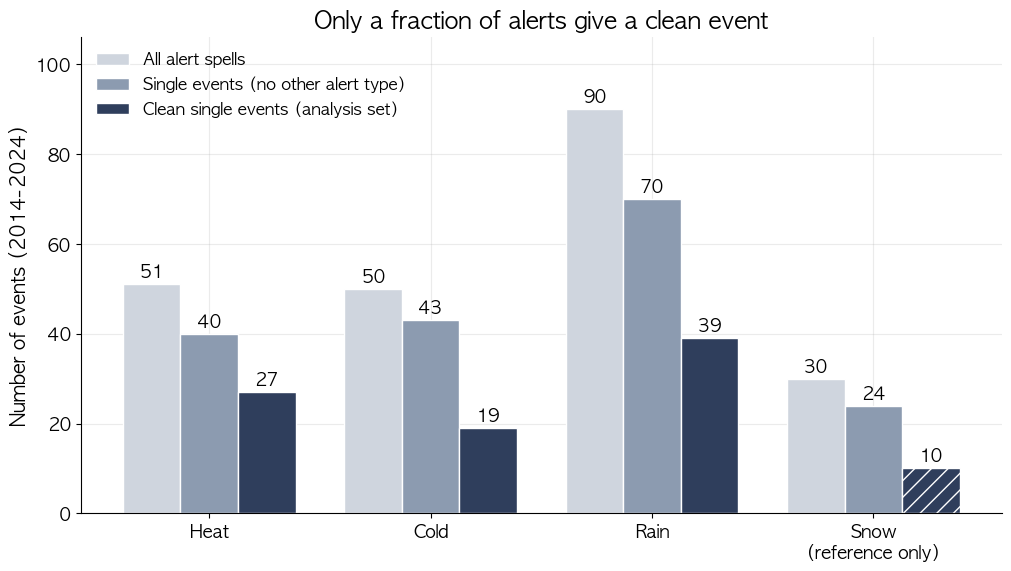

In [5]:
cal = mi[mi.station == STATIONS[0]].set_index('date').sort_index()
def n_runs(col):
    a = (cal[col] == 1)
    return int((a & ~a.shift(fill_value=False)).sum())                  # 켜진 구간 수
ec = pd.read_csv(RESULTS / 'event_counts.csv')
single = ec[ec.기준 == '단일(주 분석)']
KIND_EN = {'폭염': 'Heat', '한파': 'Cold', '호우': 'Rain', '대설': 'Snow'}
kinds = list(EVENT_TYPES)
all_runs = [n_runs(EVENT_TYPES[k]) for k in kinds]
single_all = [int(single[(single.종류 == k) & single.단계.str.startswith('0')]['train+val'].iloc[0]) for k in kinds]
single_clean = [int(single[(single.종류 == k) & single.단계.str.startswith('4')]['train+val'].iloc[0]) for k in kinds]
fig, ax = new_fig()
x = np.arange(len(kinds)); w = 0.26
cols = ['#cfd5de', '#8c9bb0', '#2f3e5c']
labs = ['All alert spells', 'Single events (no other alert type)', 'Clean single events (analysis set)']
for j, (vals, c, lab) in enumerate(zip([all_runs, single_all, single_clean], cols, labs)):
    bars = ax.bar(x + (j - 1) * w, vals, w, color=c, label=lab, edgecolor='white')
    for i, (b, v) in enumerate(zip(bars, vals)):
        if kinds[i] == '대설' and j == 2:
            b.set_hatch('//'); b.set_edgecolor('white')
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, str(v), ha='center', va='bottom', fontsize=13, fontweight='bold' if j == 2 else 'normal')
ax.set_xticks(x); ax.set_xticklabels([KIND_EN[k] + ('\n(reference only)' if k == '대설' else '') for k in kinds])
ax.set_ylabel('Number of events (2014-2024)'); ax.set_ylim(0, max(all_runs) * 1.18)
ax.set_title('Only a fraction of alerts give a clean event')
ax.legend(loc='upper left', frameon=False)
save(fig, 'fig01_events_count.png')

### 그림 2. 시청역 집회 토요일 (`fig02_cityhall_rally`)

**메시지**: 집회가 있던 토요일에 시청역 이용객은 전년 같은 시기 토요일보다 **2배 이상** 늘었지만 다른 8개 역은 거의 변화가 없어서, 시청역 집회일을 가린 것이 타당합니다. 전년 같은 날짜 구간의 토요일 평균과 비교했습니다. **두 번째 기간은 2025년 자료를 쓰지 않으려고 2024년 12월 토요일(4일)만 씁니다.**

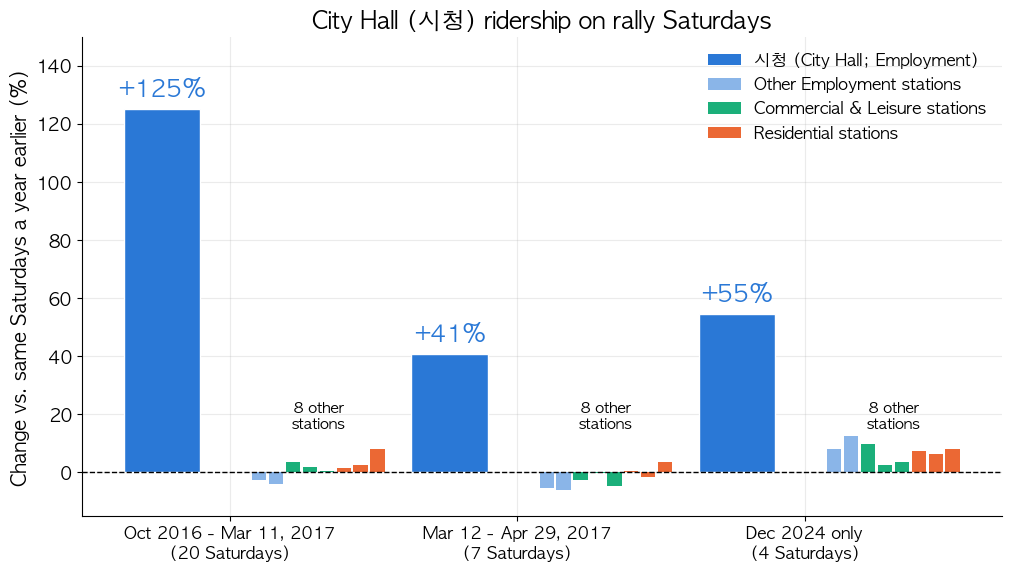

In [6]:
s_all = mi.pivot(index='date', columns='station', values='total')
periods = [('2016-10-29', '2017-03-11', 'Oct 2016 - Mar 11, 2017'), ('2017-03-12', '2017-04-29', 'Mar 12 - Apr 29, 2017'), ('2024-12-07', '2024-12-31', 'Dec 2024 only')]
def sat_change(st, a, b):
    s = s_all[st]
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    cur = s[a:b]; cur = cur[cur.index.dayofweek == 5]
    prev = s[a - pd.DateOffset(years=1):b - pd.DateOffset(years=1)]; prev = prev[prev.index.dayofweek == 5]
    return (cur.mean() / prev.mean() - 1) * 100, len(cur)
others = [s for s in STATIONS if s != '시청']
chg = {p[2]: {s: sat_change(s, p[0], p[1]) for s in STATIONS} for p in periods}
fig, ax = new_fig()
for i, (a, b, lab) in enumerate(periods):
    x0 = i * 3.4
    v, n = chg[lab]['시청']
    ax.bar(x0, v, 0.9, color=TYPE_COLORS['Employment'], edgecolor='white')
    ax.text(x0, v + 3, f'+{v:.0f}%', ha='center', va='bottom', fontsize=17, fontweight='bold', color=TYPE_COLORS['Employment'])
    for j, s in enumerate(others):
        vv = chg[lab][s][0]
        ax.bar(x0 + 1.15 + j * 0.2, vv, 0.17, color=TYPE_COLORS[STYPE[s]], alpha=0.55 if STYPE[s] == 'Employment' else 1.0)
    ax.text(x0 + 1.15 + 3.5 * 0.2, 14, '8 other\nstations', ha='center', va='bottom', fontsize=11)
ax.axhline(0, color='k', ls='--', lw=1)
ax.set_xticks([i * 3.4 + 0.8 for i in range(3)])
ax.set_xticklabels([f'{lab}\n({chg[lab]["시청"][1]} Saturdays)' for _, _, lab in periods], fontsize=12)
ax.set_ylabel('Change vs. same Saturdays a year earlier (%)'); ax.set_ylim(-15, 150)
ax.set_title('City Hall (시청) ridership on rally Saturdays')
handles = [Patch(facecolor=TYPE_COLORS['Employment'], label='시청 (City Hall; Employment)'), Patch(facecolor=TYPE_COLORS['Employment'], alpha=0.55, label='Other Employment stations'),
           Patch(facecolor=TYPE_COLORS['Commercial & Leisure'], label='Commercial & Leisure stations'), Patch(facecolor=TYPE_COLORS['Residential'], label='Residential stations')]
ax.legend(handles=handles, loc='upper right', frameon=False)
save(fig, 'fig02_cityhall_rally.png')

### 그림 3. 가리기 예시 (`fig03_masking_example`)

**메시지**: 휴일·명절·근로자의 날처럼 평소와 다른 날은 이용량이 크게 떨어지므로 **모델에서 가려(NaN) 학습에 쓰지 않습니다** (역삼, 2019년). 회색 음영이 가린 날입니다.

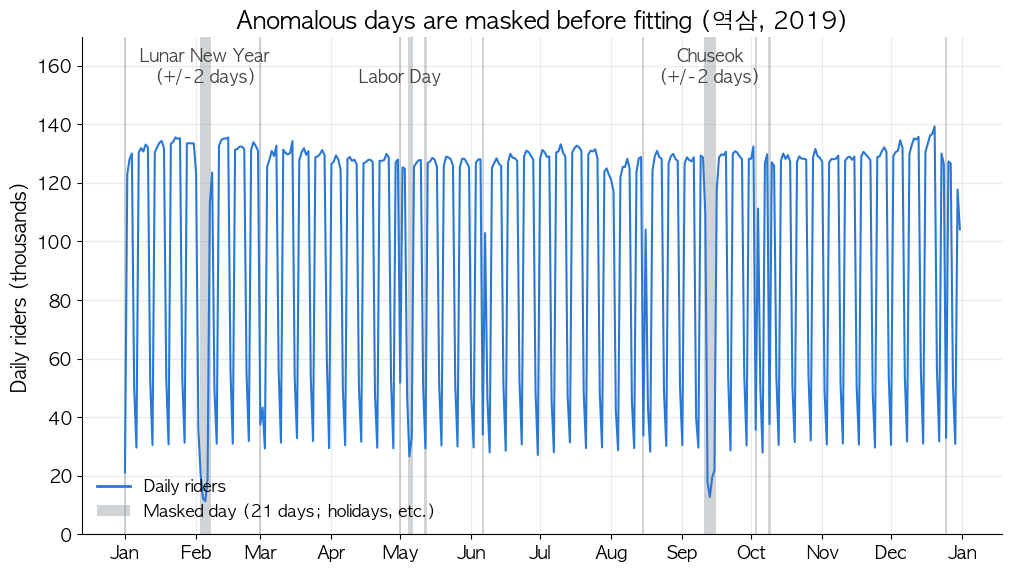

In [7]:
ys = mi[(mi.station == '역삼') & (mi.date.dt.year == 2019)].set_index('date')
masked = ys[MASK_COLS].sum(axis=1) > 0
fig, ax = new_fig()
# 연속된 가림일을 구간으로 묶어 음영
grp = (masked != masked.shift(fill_value=False)).cumsum()
spans = [(g.index.min(), g.index.max()) for _, g in masked[masked].groupby(grp[masked])]
for a, b in spans:
    ax.axvspan(a - pd.Timedelta(hours=12), b + pd.Timedelta(hours=12), color='#9aa0a6', alpha=0.45, lw=0)
ax.plot(ys.index, ys.total / 1000, color=TYPE_COLORS['Employment'], lw=1.5)
ax.set_ylabel('Daily riders (thousands)'); ax.set_ylim(0, ys.total.max() / 1000 * 1.22)
ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('Anomalous days are masked before fitting (역삼, 2019)')
def note(day, text, dx=0):
    d = pd.Timestamp(day)
    ax.text(d + pd.Timedelta(days=dx), ys.total.max() / 1000 * 1.1, text, ha='center', va='bottom', fontsize=12.5, fontweight='bold', color='#444')
note('2019-02-05', 'Lunar New Year\n(+/-2 days)')
note('2019-05-01', 'Labor Day')
note('2019-09-13', 'Chuseok\n(+/-2 days)')
ax.legend(handles=[Line2D([], [], color=TYPE_COLORS['Employment'], lw=2, label='Daily riders'), Patch(facecolor='#9aa0a6', alpha=0.45, label=f'Masked day ({int(masked.sum())} days; holidays, etc.)')],
          loc='lower left', frameon=False)
save(fig, 'fig03_masking_example.png')

### 그림 4. B 모형 누적 효과 (`fig04_B_cumulative_by_type`)

**메시지**: 폭염·한파·호우 모두 이용량을 **줄이고**, 효과가 가장 큰 쪽은 폭염은 고용형, 호우는 주거형입니다. 점은 역별 누적 효과(lag0~3 합), 막대는 95% 신뢰구간, 굵은 선은 유형 평균이며 **빈 점은 유의하지 않은 역(p ≥ 0.05)**입니다.

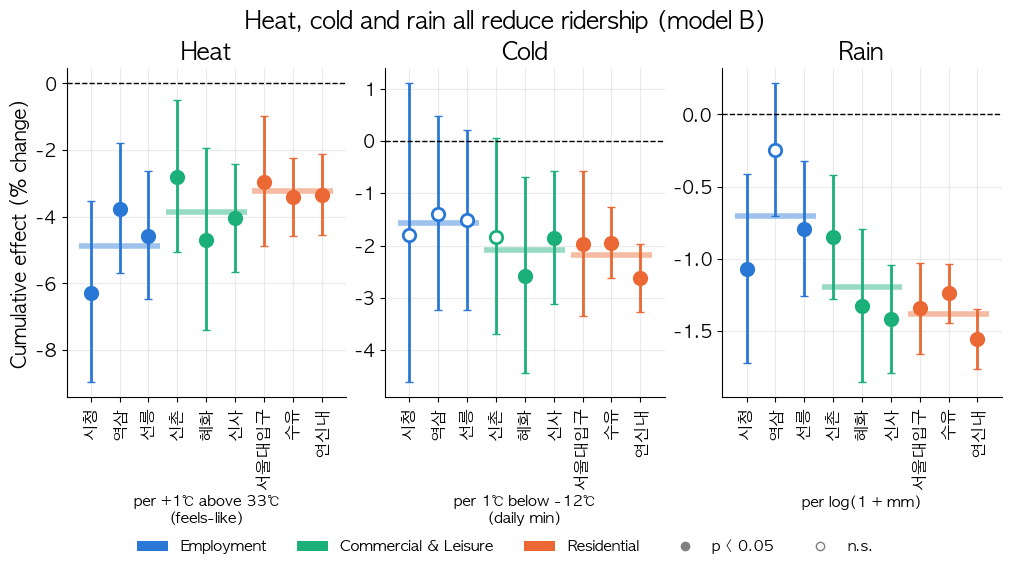

In [8]:
B = cum[cum.모형 == 'B']
VARS4 = [('heat_excess', 'Heat', 'per +1℃ above 33℃\n(feels-like)'), ('cold_excess', 'Cold', 'per 1℃ below -12℃\n(daily min)'), ('rain', 'Rain', 'per log(1 + mm)')]
fig, axes = plt.subplots(1, 3, figsize=(FIG_W, FIG_H), constrained_layout=True)
for ax, (v, title, sub) in zip(axes, VARS4):
    d = B[B.변수 == v].set_index('역').reindex(STATIONS)
    est, lo, hi = pct(d.cum_coef), pct(d.cum_coef - 1.96 * d.se), pct(d.cum_coef + 1.96 * d.se)
    for i, s in enumerate(STATIONS):
        c = TYPE_COLORS[STYPE[s]]
        ax.errorbar(i, est[s], yerr=[[est[s] - lo[s]], [hi[s] - est[s]]], fmt='none', ecolor=c, elinewidth=2, capsize=3)
        ax.scatter(i, est[s], s=80, facecolor=c if d.p[s] < 0.05 else 'white', edgecolor=c, linewidth=2, zorder=3)
    for typ, c in TYPE_COLORS.items():
        idx = [i for i, s in enumerate(STATIONS) if STYPE[s] == typ]
        ax.hlines(est.iloc[idx].mean(), min(idx) - 0.4, max(idx) + 0.4, colors=c, lw=4, alpha=0.45)
    ax.axhline(0, color='k', ls='--', lw=1)
    ax.set_xticks(range(len(STATIONS))); ax.set_xticklabels(STATIONS, rotation=90, fontsize=12)
    ax.set_title(title); ax.set_xlabel(sub, fontsize=11)
axes[0].set_ylabel('Cumulative effect (% change)')
fig.suptitle('Heat, cold and rain all reduce ridership (model B)', fontsize=17, fontweight='bold')
fig.legend(handles=type_patches + [Line2D([], [], marker='o', color='gray', mfc='gray', ls='', label='p < 0.05'), Line2D([], [], marker='o', color='gray', mfc='white', ls='', label='n.s.')],
           loc='outside lower center', ncol=5, frameon=False, fontsize=11)
save(fig, 'fig04_B_cumulative_by_type.png')

### 그림 5. 폭염 효과의 시차 (`fig05_heat_lag_profile`)

**메시지**: 폭염의 영향은 **당일보다 1~2일 뒤에 가장 크게** 나타나고 3일째에는 사라집니다 (모든 유형 공통). 선은 유형 평균, 음영은 95% 구간입니다. (구간은 역별 표준오차를 독립으로 보고 합친 근사값이며, 표준오차는 계수의 p-value에서 거꾸로 계산했습니다.)

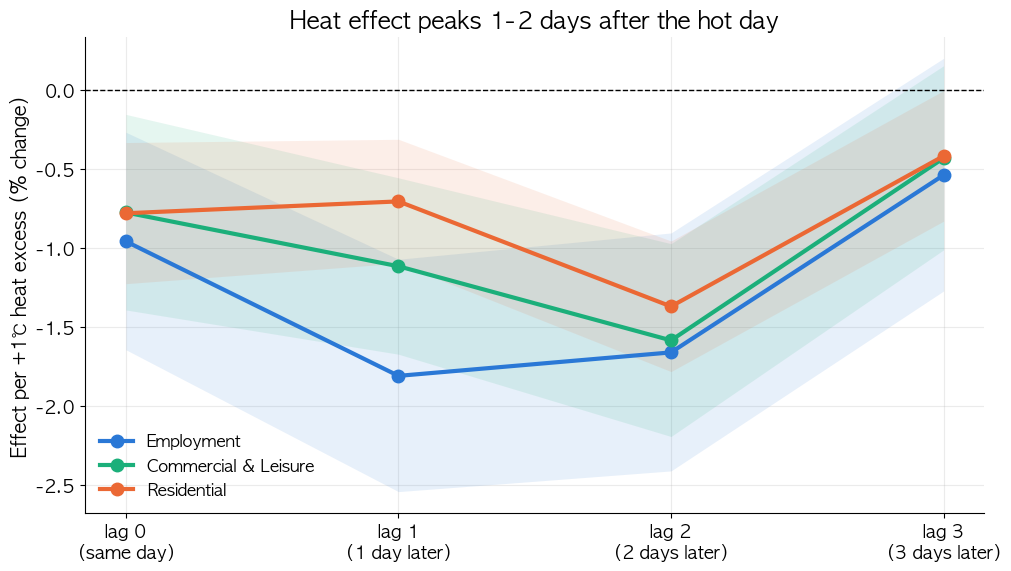

In [9]:
names = ['heat_excess', 'heat_excess_lag1', 'heat_excess_lag2', 'heat_excess_lag3']
hc = coefs[(coefs.모형 == 'B') & coefs.변수.isin(names)].copy()
hc['lag'] = hc.변수.map({n: i for i, n in enumerate(names)})
hc['se'] = hc.coef.abs() / norm.isf((hc.p.clip(1e-300, 0.999999)) / 2)        # p-value에서 표준오차 복원
fig, ax = new_fig()
for typ, c in TYPE_COLORS.items():
    g = hc[hc.유형 == typ].groupby('lag')
    m, se = g.coef.mean(), np.sqrt(g.se.apply(lambda s: (s ** 2).sum())) / g.size()
    ax.fill_between(m.index, pct(m - 1.96 * se), pct(m + 1.96 * se), color=c, alpha=0.11, lw=0)
    ax.plot(m.index, pct(m), color=c, lw=3, marker='o', ms=9, label=typ)
ax.axhline(0, color='k', ls='--', lw=1)
ax.set_xticks(range(4)); ax.set_xticklabels(['lag 0\n(same day)', 'lag 1\n(1 day later)', 'lag 2\n(2 days later)', 'lag 3\n(3 days later)'])
ax.set_ylabel('Effect per +1℃ heat excess (% change)')
ax.set_title('Heat effect peaks 1-2 days after the hot day')
ax.legend(loc='lower left', frameon=False)
save(fig, 'fig05_heat_lag_profile.png')

### 그림 6. 특보 효과: A → C (`fig06_alert_A_to_C`)

**메시지**: ASOS 날씨를 함께 통제하면(C) **특보 효과의 대부분이 유의하지 않게 됩니다** (36개 중 C에서 유의한 것은 폭염 2개, 한파 2개뿐이고 호우 특보 효과는 모두 사라짐). 화살표는 역마다 A(특보만, 원) → C(특보+ASOS, 마름모), 채운 점은 p < 0.05입니다.

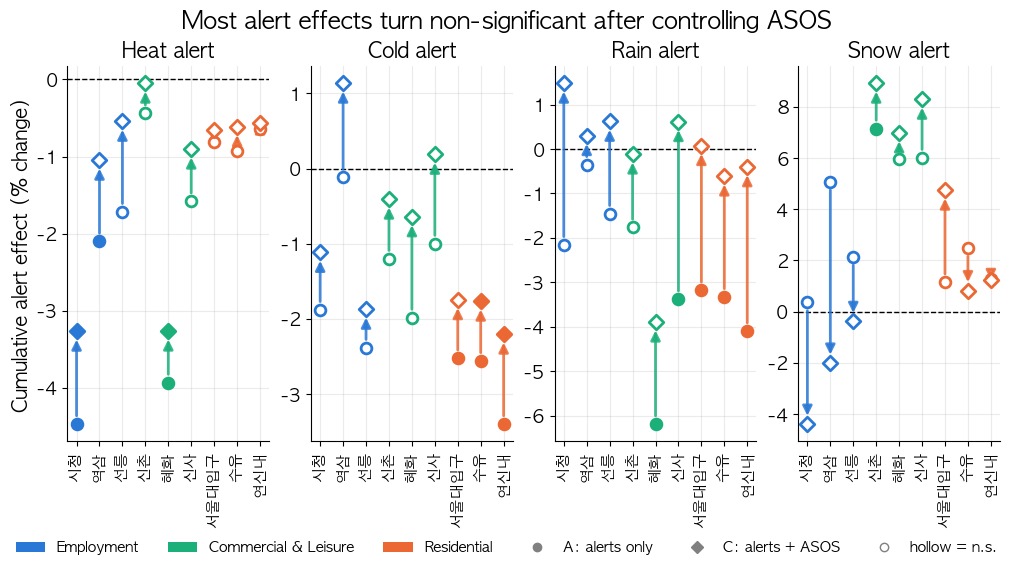

In [10]:
A_, C_ = cum[cum.모형 == 'A'], cum[cum.모형 == 'C']
ALERTS4 = [('alert_heat', 'Heat alert'), ('alert_cold', 'Cold alert'), ('alert_rain', 'Rain alert'), ('alert_snow', 'Snow alert')]
fig, axes = plt.subplots(1, 4, figsize=(FIG_W, FIG_H), constrained_layout=True)
for ax, (v, title) in zip(axes, ALERTS4):
    a = A_[A_.변수 == v].set_index('역').reindex(STATIONS); c = C_[C_.변수 == v].set_index('역').reindex(STATIONS)
    for i, s in enumerate(STATIONS):
        col = TYPE_COLORS[STYPE[s]]
        ya, yc = pct(a.cum_coef[s]), pct(c.cum_coef[s])
        ax.annotate('', xy=(i, yc), xytext=(i, ya), arrowprops=dict(arrowstyle='-|>', color=col, lw=2, shrinkA=6, shrinkB=6, alpha=0.85))
        ax.scatter(i, ya, marker='o', s=60, facecolor=col if a.p[s] < 0.05 else 'white', edgecolor=col, linewidth=2, zorder=3)
        ax.scatter(i, yc, marker='D', s=55, facecolor=col if c.p[s] < 0.05 else 'white', edgecolor=col, linewidth=2, zorder=3)
    ax.axhline(0, color='k', ls='--', lw=1)
    ax.set_xticks(range(len(STATIONS))); ax.set_xticklabels(STATIONS, rotation=90, fontsize=11)
    ax.set_title(title, fontsize=15)
axes[0].set_ylabel('Cumulative alert effect (% change)')
fig.suptitle('Most alert effects turn non-significant after controlling ASOS', fontsize=17, fontweight='bold')
fig.legend(handles=type_patches + [Line2D([], [], marker='o', color='gray', mfc='gray', ls='', label='A: alerts only'), Line2D([], [], marker='D', color='gray', mfc='gray', ls='', label='C: alerts + ASOS'),
                                    Line2D([], [], marker='o', color='gray', mfc='white', ls='', label='hollow = n.s.')], loc='outside lower center', ncol=6, frameon=False, fontsize=10.5)
save(fig, 'fig06_alert_A_to_C.png')

### 그림 7. 휴가철 더미 전/후 (`fig07_summer_vacation`)

**메시지**: 여름 휴가철 더미를 넣으면 **폭염 효과가 약 11~17% 줄어듭니다** (폭염과 휴가철이 일부 섞여 있었음). 그래도 폭염 효과는 모든 유형에서 뚜렷하게 남습니다. 막대는 유형 평균, 점은 역별 값입니다.

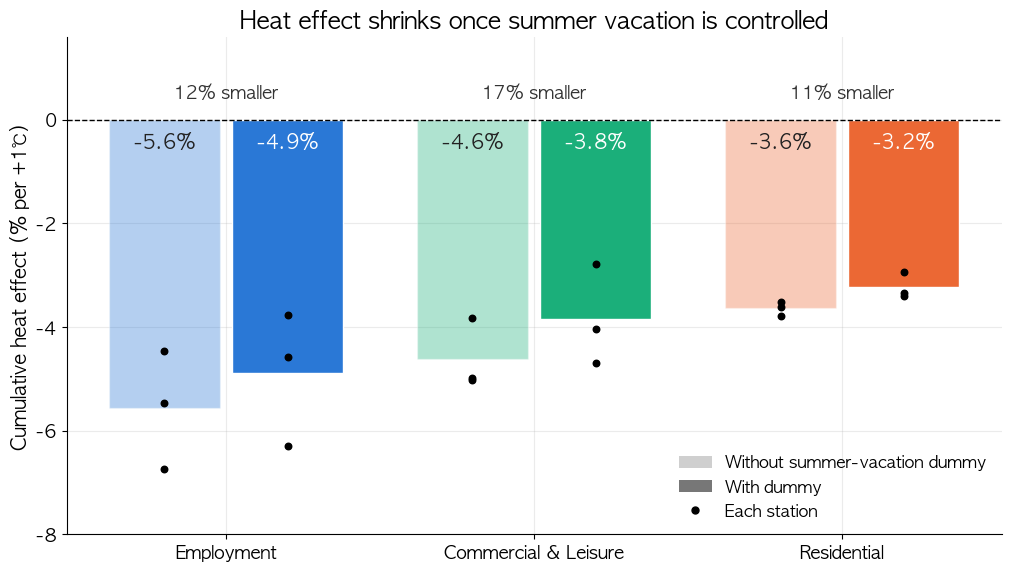

In [11]:
sv = pd.read_csv(RESULTS / 'sarimax_B_season_cumulative.csv')
h = sv[sv.변수 == 'heat_excess']
fig, ax = new_fig()
types = list(TYPE_COLORS)
for i, typ in enumerate(types):
    c = TYPE_COLORS[typ]
    for j, (ver, alpha, lab) in enumerate([('없음', 0.35, 'Without summer-vacation dummy'), ('있음', 1.0, 'With dummy')]):
        d = h[(h.유형 == typ) & (h.버전 == ver)]
        m = pct(d.cum_coef.mean())
        xx = i + (j - 0.5) * 0.4
        ax.bar(xx, m, 0.36, color=c, alpha=alpha, edgecolor='white')
        ax.scatter(np.full(len(d), xx), pct(d.cum_coef), color='k', s=22, zorder=3)
        ax.text(xx, -0.25, f'{m:.1f}%', ha='center', va='top', fontsize=14, fontweight='bold', color='white' if alpha == 1.0 else '#222')
    m0, m1 = pct(h[(h.유형 == typ) & (h.버전 == '없음')].cum_coef.mean()), pct(h[(h.유형 == typ) & (h.버전 == '있음')].cum_coef.mean())
    ax.text(i, 0.35, f'{(1 - m1 / m0) * 100:.0f}% smaller', ha='center', va='bottom', fontsize=13, color='#333')
ax.axhline(0, color='k', ls='--', lw=1)
ax.set_xticks(range(3)); ax.set_xticklabels(types); ax.set_ylim(-8, 1.6)
ax.set_ylabel('Cumulative heat effect (% per +1℃)')
ax.set_title('Heat effect shrinks once summer vacation is controlled')
ax.legend(handles=[Patch(facecolor='#777', alpha=0.35, label='Without summer-vacation dummy'), Patch(facecolor='#777', label='With dummy'), Line2D([], [], marker='o', color='k', ls='', ms=5, label='Each station')],
          loc='lower right', frameon=False)
save(fig, 'fig07_summer_vacation.png')

### 그림 8. 이벤트 따라가기: 호우 (`fig08_event_walkthrough`)

**메시지**: 같은 호우 특보에 **주거형 역은 이용객이 기준선 구간 아래로 떨어졌다가 며칠 뒤 돌아오지만, 고용형 역은 영향이 없습니다.** 선택 규칙: 단일 호우 이벤트 중 ① 주거형 역에서 충격이 있고 회복일이 관측되며(회복 지연 2일 이상이라 회복 과정이 보임) ② 고용형 3개 역은 모두 충격이 없는 이벤트를 찾아 주거형 최대 감소율이 가장 큰 것을 골랐습니다. 고용형은 그 이벤트에서 기준선과 가장 가까웠던 역을 보여 줍니다.

In [12]:
eff = pd.read_csv(RESULTS / 'event_effects.csv', parse_dates=['시작일', '종료일', '회복일'])
paths = pd.read_csv(RESULTS / 'event_daily_paths.csv', parse_dates=['date', 'end'])
r = eff[(eff.분류 == '단일') & (eff.종류 == '호우')]
cands = []
for eid, g in r.groupby('이벤트번호'):
    emp, res = g[g.유형 == 'Employment'], g[g.유형 == 'Residential']
    if (~emp.충격).all():                                           # 고용형 3개 역 모두 충격 없음
        for _, a in res[res.충격 & ~res.중도절단 & (res.회복지연일 >= 2)].iterrows():     # 주거형: 충격 + 회복 관측 + 회복 과정이 보임
            cands.append({'event': eid, 'start': a.시작일.date(), 'days': a.지속일수, 'residential': a.역, 'max_drop%': round(a['최대감소율%'], 1), 'days_below': a.n_below,
                          'recovery_delay': a.회복지연일, 'employment_max_drop%': ', '.join(f"{x.역}:{x['최대감소율%']:.1f}" for _, x in emp.iterrows())})
cands = pd.DataFrame(cands).sort_values('max_drop%', ascending=False).reset_index(drop=True)
print('후보 (주거형 충격+회복 관측, 고용형 무충격):'); print(cands.to_string())
pick = cands.iloc[0]
eid, st_res = pick.event, pick.residential
emp_rows = r[(r.이벤트번호 == eid) & (r.유형 == 'Employment')]
st_emp = emp_rows.loc[emp_rows['최대감소율%'].abs().idxmin(), '역']       # 고용형 중 기준선에 가장 가까웠던 역
print(f'선택: {eid} ({pick.start}, {pick.days}일), 주거형 {st_res}, 고용형 {st_emp}')

후보 (주거형 충격+회복 관측, 고용형 무충격):
      event       start  days residential  max_drop%  days_below  recovery_delay      employment_max_drop%
0  단일-호우-66  2023-07-13     2         연신내        8.7           2             2.0  시청:-3.9, 역삼:-0.2, 선릉:2.6
1  단일-호우-55  2022-07-16     1         연신내        7.9           1             2.0  시청:-59.9, 역삼:7.2, 선릉:4.5
선택: 단일-호우-66 (2023-07-13, 2일), 주거형 연신내, 고용형 역삼


**그림 8 그리기**: 위 패널은 주거형, 아래 패널은 고용형 역입니다. 검은 선이 실제 이용객, 점선이 기준선, 음영이 95% 구간입니다. 빨간 ×는 특보 기간 중 구간 아래로 떨어진 날(충격일), 초록 세로선은 회복일(구간 안에 2일 연속 머문 첫날), 붉은 음영은 특보 기간, 회색 빗금은 다음 특보 기간입니다.

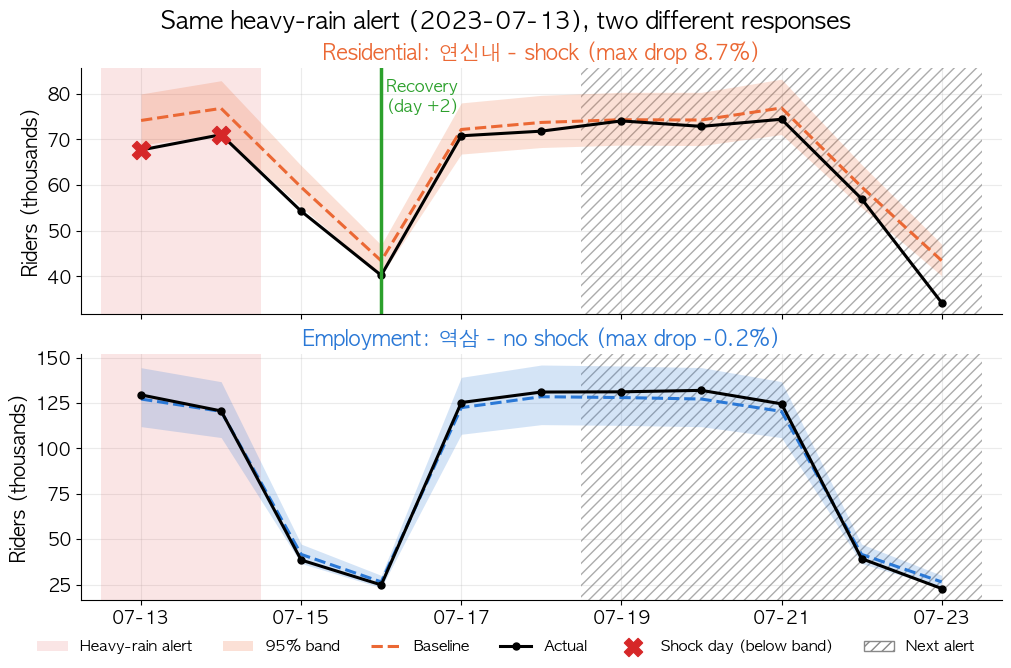

In [13]:
ev_row = r[r.이벤트번호 == eid].iloc[0]
s0, e0 = ev_row.시작일, ev_row.종료일
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 6.6), constrained_layout=True, sharex=True)
for ax, st, tag in zip(axes, [st_res, st_emp], ['shock', 'no shock']):
    g = paths[(paths.id == eid) & (paths.역 == st)].set_index('date')
    g = g.loc[:s0 + pd.Timedelta(days=10)]                           # 시작 후 10일까지만 보여 줌
    c = TYPE_COLORS[STYPE[st]]
    er = r[(r.이벤트번호 == eid) & (r.역 == st)].iloc[0]
    ax.axvspan(s0 - pd.Timedelta(hours=12), e0 + pd.Timedelta(hours=12), color='#e45756', alpha=0.15, lw=0, label='Heavy-rain alert')
    nxt = g.index[(g.alert_day) & (g.index > e0)]
    for d in nxt:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), facecolor='none', edgecolor='#888', hatch='///', lw=0, alpha=0.7)
    ax.fill_between(g.index, g.lower / 1000, g.upper / 1000, color=c, alpha=0.2, lw=0, label='95% band')
    ax.plot(g.index, g.base / 1000, color=c, ls='--', lw=2.2, label='Baseline')
    ax.plot(g.index, g.actual / 1000, color='k', lw=2.2, marker='o', ms=5, label='Actual')
    shock_days = g.loc[s0:e0][g.loc[s0:e0].actual < g.loc[s0:e0].lower]
    ax.scatter(shock_days.index, shock_days.actual / 1000, marker='X', s=170, color='#d62728', zorder=5, label='Shock day (below band)')
    if er.충격 and pd.notna(er.회복일):                              # 충격이 있었던 역만 회복일 표시
        ax.axvline(er.회복일, color='#2ca02c', lw=2.5)
        ax.text(er.회복일, g.upper.max() / 1000 * 1.0, ' Recovery\n (day +%d)' % er.회복지연일, color='#2ca02c', fontsize=12, va='top', fontweight='bold')
    ax.set_ylabel('Riders (thousands)')
    ax.set_title(f'{STYPE[st]}: {st} - {tag} (max drop {er["최대감소율%"]:.1f}%)', fontsize=15, color=c)
    ax.set_xlim(s0 - pd.Timedelta(hours=18), s0 + pd.Timedelta(days=10, hours=18))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
h, l = axes[0].get_legend_handles_labels()
fig.legend(h + [Patch(facecolor='none', edgecolor='#888', hatch='///', label='Next alert')], l + ['Next alert'], loc='outside lower center', ncol=6, frameon=False, fontsize=11)
fig.suptitle(f'Same heavy-rain alert ({s0.date()}), two different responses', fontsize=17, fontweight='bold')
save(fig, 'fig08_event_walkthrough.png')

### 그림 9. 유형별 충격 비율 (`fig09_shock_by_type`)

**메시지**: 특보에 이용객이 구간 아래로 떨어지는 경우는 대체로 드물고, **호우는 주거형(약 50%)에서만 뚜렷**합니다. 막대 위 숫자는 충격 비율과 이벤트 수(n)입니다. 대설은 이벤트가 적어 참고용(빗금)입니다. (단일 이벤트, 2014~2024)

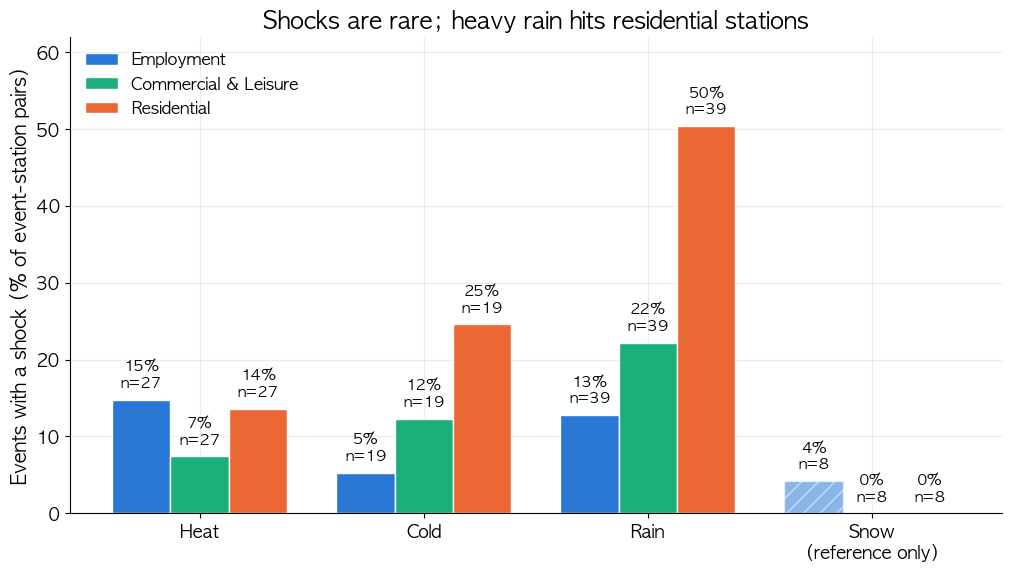

In [14]:
sm = pd.read_csv(RESULTS / 'event_summary_by_type.csv')
sm = sm[sm.결과 == '단일(주 분석)']
fig, ax = new_fig()
w = 0.26; x = np.arange(len(kinds))
for j, typ in enumerate(TYPE_COLORS):
    d = sm[sm.유형 == typ].set_index('종류').reindex(kinds)
    bars = ax.bar(x + (j - 1) * w, d['충격 비율'] * 100, w, color=TYPE_COLORS[typ], label=typ, edgecolor='white')
    for k, (b, (_, row)) in enumerate(zip(bars, d.iterrows())):
        if kinds[k] == '대설':
            b.set_hatch('//'); b.set_alpha(0.55)
        ax.text(b.get_x() + b.get_width() / 2, row['충격 비율'] * 100 + 1.2, f"{row['충격 비율'] * 100:.0f}%\nn={int(row['이벤트 수'])}", ha='center', va='bottom', fontsize=11)
ax.set_xticks(x); ax.set_xticklabels([KIND_EN[k] + ('\n(reference only)' if k == '대설' else '') for k in kinds])
ax.set_ylabel('Events with a shock (% of event-station pairs)'); ax.set_ylim(0, 62)
ax.set_title('Shocks are rare; heavy rain hits residential stations')
ax.legend(loc='upper left', frameon=False)
save(fig, 'fig09_shock_by_type.png')

### 그림 10. 회복 (`fig10_recovery`)

**메시지**: 충격이 있었던 경우 대부분 **해제 후 1일 안에 돌아오고**, 확인 창이 짧아 판정이 안 되는 **중도절단은 m(구간 안에 머물러야 하는 연속 일수)이 클수록 늘어납니다** (m=2가 주 분석). 막대는 충격이 있었던 이벤트×역 중 회복 결과의 비율, 막대 위 숫자는 충격 건수입니다. 회복 지연 분포는 `event_daily_paths.csv`에서 04번과 같은 규칙으로 다시 계산했습니다.

m=2 중도절단 비율(04번 표와 같아야 함): {'대설': 0.0, '폭염': 0.621, '한파': 0.167, '호우': 0.55}


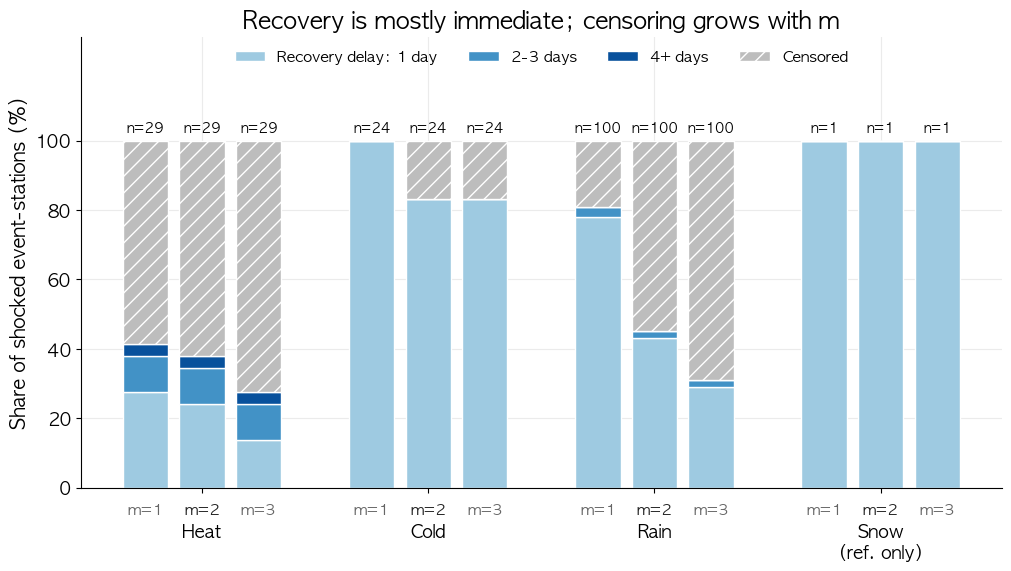

In [15]:
ONE = pd.Timedelta(days=1)
def recovery_delay(g, e, m):
    post = g.loc[e + ONE:]
    stop = post.index[post.mask_day | post.alert_day]                    # 다음 특보 또는 가림일 전날까지만 확인
    if len(stop):
        post = post.loc[:stop[0] - ONE]
    inside = ((post.actual >= post.lower) & (post.actual <= post.upper)).astype(int)
    if len(post) >= m:
        run = inside.rolling(m).sum().shift(-(m - 1)) == m
        idx = run[run].index
        if len(idx):
            return (idx[0] - e).days
    return np.nan                                                        # 중도절단
shocked = eff[(eff.분류 == '단일') & eff.충격]
pg = {k: g.set_index('date') for k, g in paths.groupby(['id', '역'])}
rows = []
for _, r_ in shocked.iterrows():
    g = pg[(r_.이벤트번호, r_.역)]
    for m in KM_CANDIDATES:
        rows.append({'종류': r_.종류, 'm': m, 'delay': recovery_delay(g, r_.종료일, m)})
rec = pd.DataFrame(rows)
def cat(d):
    return 'Censored' if pd.isna(d) else ('1 day' if d == 1 else ('2-3 days' if d <= 3 else '4+ days'))
rec['cat'] = rec.delay.map(cat)
CATS = ['1 day', '2-3 days', '4+ days', 'Censored']
CCOL = {'1 day': '#9ecae1', '2-3 days': '#4292c6', '4+ days': '#08519c', 'Censored': '#bdbdbd'}
chk = rec[rec.m == RECOVERY_M].groupby('종류').delay.apply(lambda s: s.isna().mean()).round(3).to_dict()
print('m=%d 중도절단 비율(04번 표와 같아야 함):' % RECOVERY_M, chk)
fig, ax = new_fig()
for ki, k in enumerate(kinds):
    for mj, m in enumerate(KM_CANDIDATES):
        d = rec[(rec.종류 == k) & (rec.m == m)]
        xx = ki * 4 + mj
        bottom = 0
        for cname in CATS:
            f = (d.cat == cname).mean() * 100 if len(d) else 0
            ax.bar(xx, f, 0.8, bottom=bottom, color=CCOL[cname], edgecolor='white', hatch='//' if (cname == 'Censored') else None)
            bottom += f
        ax.text(xx, 101.5, f'n={len(d)}', ha='center', va='bottom', fontsize=10)
        ax.text(xx, -4.5, f'm={m}', ha='center', va='top', fontsize=11, fontweight='bold' if m == RECOVERY_M else 'normal', color='#222' if m == RECOVERY_M else '#666')
ax.set_xticks([ki * 4 + 1 for ki in range(len(kinds))]); ax.set_xticklabels([KIND_EN[k] + ('\n(ref. only)' if k == '대설' else '') for k in kinds])
ax.tick_params(axis='x', pad=22)
ax.set_ylabel('Share of shocked event-stations (%)'); ax.set_ylim(0, 130)
ax.set_yticks(range(0, 101, 20))
ax.set_title('Recovery is mostly immediate; censoring grows with m')
ax.legend(handles=[Patch(facecolor=CCOL[c], label=('Recovery delay: ' if c == '1 day' else '') + c, hatch='//' if c == 'Censored' else None, edgecolor='white') for c in CATS], loc='upper center', frameon=False, ncol=4, fontsize=11)
save(fig, 'fig10_recovery.png')

### 그림 11. Naive → N → A → B 단계 (`fig11_model_steps`)

**메시지**: 하루 앞 예측 오차(MAPE)는 **이상일을 가리고 달력 더미를 넣은 것만으로 절반 가까이(−43%) 줄고**, 특보(A)와 날씨(B)를 더해도 추가 개선은 아주 작습니다. 선은 유형별 평균(9개 역).

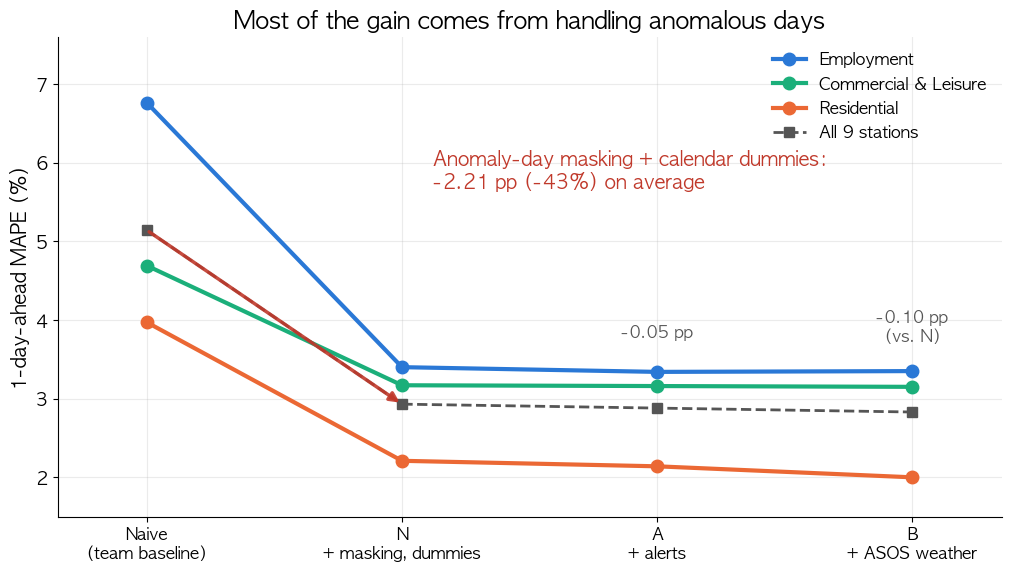

In [16]:
bt = pd.read_csv(RESULTS / 'model_compare_by_type.csv')
roll = bt[bt.방식 == '(가) 하루 앞 롤링']
order = ['Naive', 'N', 'A', 'B']
xlab = ['Naive\n(team baseline)', 'N\n+ masking, dummies', 'A\n+ alerts', 'B\n+ ASOS weather']
fig, ax = new_fig()
for typ, c in TYPE_COLORS.items():
    d = roll[roll.유형 == typ].set_index('모형').MAPE.reindex(order)
    ax.plot(range(4), d.values, color=c, lw=3, marker='o', ms=9, label=typ)
tot = roll[roll.유형 == '전체(9개 역)'].set_index('모형').MAPE.reindex(order)
ax.plot(range(4), tot.values, color='#555', lw=2, ls='--', marker='s', ms=7, label='All 9 stations')
ax.annotate('', xy=(1, tot['N']), xytext=(0, tot['Naive']), arrowprops=dict(arrowstyle='-|>', color='#c0392b', lw=2.5, alpha=0.9))
ax.text(1.12, 5.9, f'Anomaly-day masking + calendar dummies:\n-{tot["Naive"] - tot["N"]:.2f} pp (-{(1 - tot["N"] / tot["Naive"]) * 100:.0f}%) on average', ha='left', va='center', fontsize=14, color='#c0392b', fontweight='bold')
ax.text(2.0, tot['A'] + 0.9, f'-{tot["N"] - tot["A"]:.2f} pp', ha='center', fontsize=12, color='#555')
ax.text(3.0, tot['B'] + 0.9, f'-{tot["N"] - tot["B"]:.2f} pp\n(vs. N)', ha='center', fontsize=12, color='#555')
ax.set_xticks(range(4)); ax.set_xticklabels(xlab, fontsize=12)
ax.set_xlim(-0.35, 3.35)
ax.set_ylabel('1-day-ahead MAPE (%)'); ax.set_ylim(1.5, 7.6)
ax.set_title('Most of the gain comes from handling anomalous days')
ax.legend(loc='upper right', frameon=False)
save(fig, 'fig11_model_steps.png')

### 그림 12. 두 가지 평가 방식 (`fig12_model_compare_two_ways`)

**메시지**: **하루 앞 예측**에서는 N → A/B 개선이 작고, **365일 한 번에** 예측에서는 더 커 보이지만 그 A·B_lag·B는 2024년 실제 특보·날씨를 입력으로 준 **사후 상한선**(빗금)이라 실제 예측 성능이 아닙니다. 막대는 9개 역 평균 MAPE입니다.

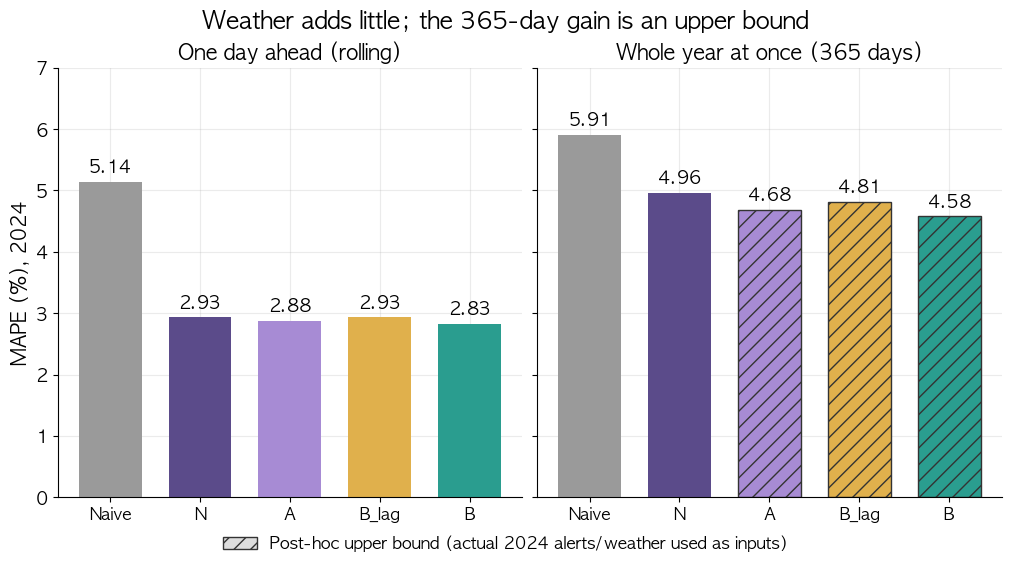

In [17]:
tot = bt[bt.유형 == '전체(9개 역)']
MODELS = ['Naive', 'N', 'A', 'B_lag', 'B']
MCOL = {'Naive': '#9a9a9a', 'N': '#5b4b8a', 'A': '#a78bd4', 'B_lag': '#e0b04c', 'B': '#2a9d8f'}
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H), constrained_layout=True, sharey=True)
for ax, mode, title in zip(axes, ['(가) 하루 앞 롤링', '(나) 365일 한 번에'], ['One day ahead (rolling)', 'Whole year at once (365 days)']):
    d = tot[tot.방식 == mode].set_index('모형').MAPE.reindex(MODELS)
    for i, m in enumerate(MODELS):
        hatch = '//' if (mode.startswith('(나)') and m in ('A', 'B_lag', 'B')) else None
        ax.bar(i, d[m], 0.7, color=MCOL[m], hatch=hatch, edgecolor='white' if not hatch else '#333', linewidth=0 if not hatch else 1)
        ax.text(i, d[m] + 0.1, f'{d[m]:.2f}', ha='center', va='bottom', fontsize=13, fontweight='bold')
    ax.set_xticks(range(5)); ax.set_xticklabels(MODELS, fontsize=12)
    ax.set_title(title, fontsize=15); ax.set_ylim(0, 7)
axes[0].set_ylabel('MAPE (%), 2024')
fig.legend(handles=[Patch(facecolor='#ddd', hatch='//', edgecolor='#333', label='Post-hoc upper bound (actual 2024 alerts/weather used as inputs)')], loc='outside lower center', frameon=False, fontsize=12)
fig.suptitle('Weather adds little; the 365-day gain is an upper bound', fontsize=17, fontweight='bold')
save(fig, 'fig12_model_compare_two_ways.png')

### 저장된 그림 목록

`figures/ppt/`에 저장된 PNG의 크기(픽셀)와 용량을 확인합니다 (가로 10인치 × 300dpi = 3000픽셀).

In [18]:
from PIL import Image
rows = []
for p in sorted(FIG_PPT.glob('fig*.png')):
    im = Image.open(p)
    rows.append({'file': p.name, 'size_px': f'{im.size[0]} x {im.size[1]}', 'width_in': round(im.size[0] / FIG_DPI, 2), 'KB': p.stat().st_size // 1024})
pd.DataFrame(rows)

,file,size_px,width_in,KB
0,fig01_events_count.png,3000 x 1680,10.0,192
1,fig02_cityhall_rally.png,3000 x 1680,10.0,250
2,fig03_masking_example.png,3000 x 1680,10.0,569
3,fig04_B_cumulative_by_type.png,3000 x 1680,10.0,255
4,fig05_heat_lag_profile.png,3000 x 1680,10.0,328
5,fig06_alert_A_to_C.png,3000 x 1680,10.0,330
6,fig07_summer_vacation.png,3000 x 1680,10.0,207
7,fig08_event_walkthrough.png,3000 x 1980,10.0,553
8,fig09_shock_by_type.png,3000 x 1680,10.0,227
9,fig10_recovery.png,3000 x 1680,10.0,197
